# Predictive maintenance on the AI4I 2020 dataset

I come from a mechanical background, so flagging a machine failure before it happens is the kind of
problem I actually enjoy. I used the AI4I 2020 dataset (10,000 synthetic machining runs) to see how
far you can get predicting failure from a handful of sensor readings: temperatures, rotational speed,
torque and tool wear.

The thing to keep in mind the whole way through is that only about 3.4% of the runs fail. That makes
plain accuracy almost meaningless, a model that predicts "no failure" every single time already scores
about 96%. What I actually care about is **recall on the failure class**, because a missed failure is
the costly one.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("data/ai4i2020.csv")
print(df.shape)
df.head()

(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## First look

Columns are straightforward. `Machine failure` is the label. The five columns after it (TWF, HDF, PWF,
OSF, RNF) are the specific failure modes, tool wear, heat dissipation, power, overstrain and random.
Those are basically the label broken down by cause, so I will drop them before modelling, otherwise the
model is just reading the answer.

failure rate: 3.39%  (339 of 10000)

failure modes:
HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64


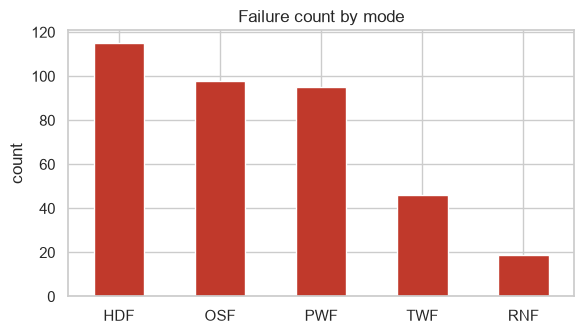

In [2]:
fail_rate = df["Machine failure"].mean()
print(f"failure rate: {fail_rate:.2%}  ({df['Machine failure'].sum()} of {len(df)})")

modes = df[["TWF","HDF","PWF","OSF","RNF"]].sum().sort_values(ascending=False)
print("\nfailure modes:")
print(modes)

fig, ax = plt.subplots(figsize=(6,3.5))
modes.plot(kind="bar", color="#c0392b", ax=ax)
ax.set_title("Failure count by mode")
ax.set_ylabel("count"); ax.set_xlabel("")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("figures/failure_modes.png", dpi=110); plt.show()

## A bit of domain feature engineering

Two things jumped out from the physics before I touched any model.

- Mechanical power is roughly torque times angular speed. That should line up with the power failure
  mode (PWF), so I added a `power` feature (torque x rotational speed, converted to watts).
- The gap between process temperature and air temperature is what the heat failure mode (HDF) is about,
  so I added `temp_diff`.

These are cheap to compute and they give the model something closer to what actually drives the
failures, instead of making it rediscover the relationship from raw columns.

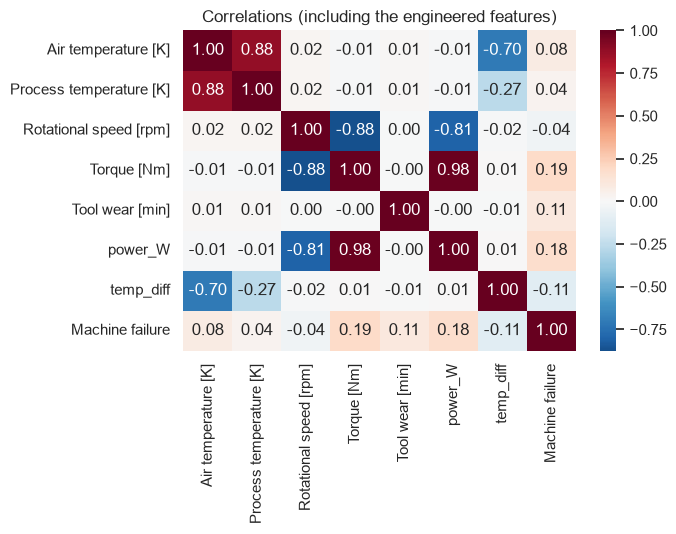

In [3]:
df["power_W"] = df["Torque [Nm]"] * df["Rotational speed [rpm]"] * 2 * np.pi / 60
df["temp_diff"] = df["Process temperature [K]"] - df["Air temperature [K]"]

num_cols = ["Air temperature [K]","Process temperature [K]","Rotational speed [rpm]",
            "Torque [Nm]","Tool wear [min]","power_W","temp_diff","Machine failure"]
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(7,5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlations (including the engineered features)")
plt.tight_layout(); plt.savefig("figures/correlations.png", dpi=110); plt.show()

The correlations are modest, which is expected, no single reading flips a machine into failure on its
own. Torque and the power feature have the clearest positive link to failure, and tool wear is in there
too. Let me look at how the distributions actually separate.

C:\Users\akeem\AppData\Local\Temp\ipykernel_24392\4084622082.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Machine failure", y=c, ax=a, palette=["#2e86de","#c0392b"])
C:\Users\akeem\AppData\Local\Temp\ipykernel_24392\4084622082.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Machine failure", y=c, ax=a, palette=["#2e86de","#c0392b"])
C:\Users\akeem\AppData\Local\Temp\ipykernel_24392\4084622082.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Machine failure", y=c, ax=a, palette=["#2e86de","#c0

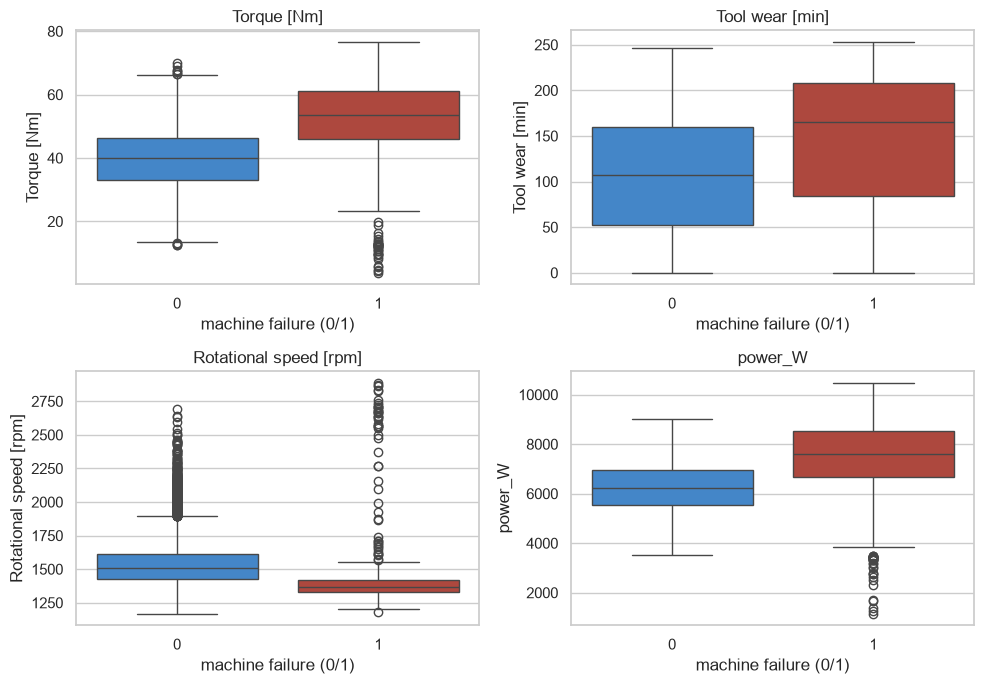

In [4]:
feat = ["Torque [Nm]","Tool wear [min]","Rotational speed [rpm]","power_W"]
fig, axes = plt.subplots(2,2, figsize=(10,7))
for a, c in zip(axes.ravel(), feat):
    sns.boxplot(data=df, x="Machine failure", y=c, ax=a, palette=["#2e86de","#c0392b"])
    a.set_title(c); a.set_xlabel("machine failure (0/1)")
plt.tight_layout(); plt.savefig("figures/feature_boxplots.png", dpi=110); plt.show()

Failures sit at both ends for torque and speed (very high torque at low speed, or the reverse), which
matches the overstrain and power modes. Tool wear skews higher for failures too. So there is signal, it
is just not linearly clean, which already hints a tree model will beat a linear one here.

## Modelling

Setup: drop the identifier columns and the five failure-mode columns (label leakage), one-hot encode the
machine `Type` (L/M/H), and use a stratified train/test split so the tiny failure class is represented in
both halves. I will try a logistic regression as a baseline and a random forest, both with balanced class
weights so the model is not allowed to ignore the failure class.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_recall_curve)

drop = ["UDI","Product ID","Machine failure","TWF","HDF","PWF","OSF","RNF"]
X = df.drop(columns=drop)
X = pd.get_dummies(X, columns=["Type"], drop_first=True)
y = df["Machine failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
print("train", X_train.shape, "test", X_test.shape, "test failures:", int(y_test.sum()))

train (7500, 9) test (2500, 9) test failures: 85


In [6]:
# Baseline: logistic regression (scaled)
scaler = StandardScaler()
Xtr_s = scaler.fit_transform(X_train); Xte_s = scaler.transform(X_test)
logit = LogisticRegression(max_iter=2000, class_weight="balanced")
logit.fit(Xtr_s, y_train)
p_logit = logit.predict(Xte_s)
print("Logistic regression")
print(classification_report(y_test, p_logit, digits=3))
print("ROC-AUC:", round(roc_auc_score(y_test, logit.predict_proba(Xte_s)[:,1]), 3))

Logistic regression
              precision    recall  f1-score   support

           0      0.992     0.859     0.921      2415
           1      0.169     0.812     0.279        85

    accuracy                          0.858      2500
   macro avg      0.581     0.835     0.600      2500
weighted avg      0.964     0.858     0.899      2500

ROC-AUC: 0.914


In [7]:
# Random forest
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
p_rf = rf.predict(X_test)
proba_rf = rf.predict_proba(X_test)[:,1]
print("Random forest")
print(classification_report(y_test, p_rf, digits=3))
auc_rf = roc_auc_score(y_test, proba_rf)
print("ROC-AUC:", round(auc_rf, 3))

Random forest
              precision    recall  f1-score   support

           0      0.993     0.995     0.994      2415
           1      0.852     0.812     0.831        85

    accuracy                          0.989      2500
   macro avg      0.923     0.903     0.913      2500
weighted avg      0.989     0.989     0.989      2500

ROC-AUC: 0.969


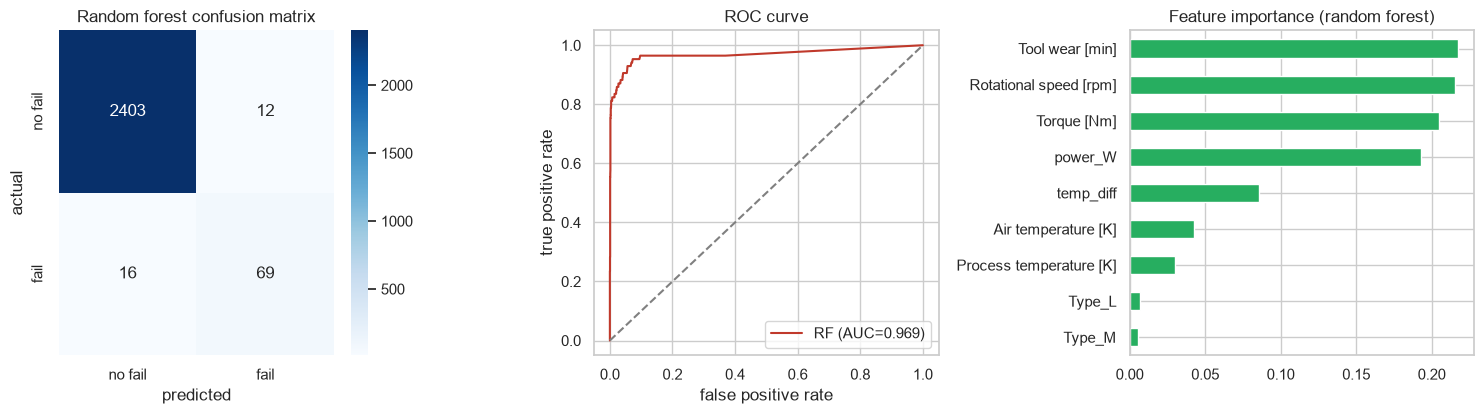

Tool wear [min]            0.217127
Rotational speed [rpm]     0.215234
Torque [Nm]                0.204870
power_W                    0.192766
temp_diff                  0.085382
Air temperature [K]        0.042689
Process temperature [K]    0.029745
Type_L                     0.006665
Type_M                     0.005522
dtype: float64

In [8]:
# Confusion matrix, ROC curve, feature importance
fig, axes = plt.subplots(1,3, figsize=(15,4.3))

cm = confusion_matrix(y_test, p_rf)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["no fail","fail"], yticklabels=["no fail","fail"])
axes[0].set_title("Random forest confusion matrix")
axes[0].set_ylabel("actual"); axes[0].set_xlabel("predicted")

fpr, tpr, _ = roc_curve(y_test, proba_rf)
axes[1].plot(fpr, tpr, color="#c0392b", label=f"RF (AUC={auc_rf:.3f})")
axes[1].plot([0,1],[0,1], "--", color="grey")
axes[1].set_title("ROC curve"); axes[1].set_xlabel("false positive rate")
axes[1].set_ylabel("true positive rate"); axes[1].legend()

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", ax=axes[2], color="#27ae60")
axes[2].set_title("Feature importance (random forest)")
plt.tight_layout(); plt.savefig("figures/rf_results.png", dpi=110); plt.show()
imp.sort_values(ascending=False)

## Where the default threshold leaves us, and tuning it

The random forest already does well, but the default 0.5 cutoff is not sacred. Because missing a failure
matters more than a false alarm here, it is worth seeing what moving the threshold does to the
recall/precision trade-off.

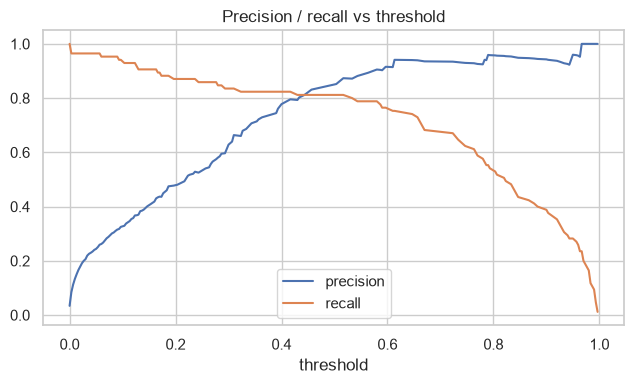

At threshold 0.13: recall=0.906, precision=0.370
[[2284  131]
 [   8   77]]


In [9]:
prec, rec, thr = precision_recall_curve(y_test, proba_rf)
fig, ax = plt.subplots(figsize=(6.5,4))
ax.plot(thr, prec[:-1], label="precision")
ax.plot(thr, rec[:-1], label="recall")
ax.set_xlabel("threshold"); ax.set_title("Precision / recall vs threshold")
ax.legend(); plt.tight_layout(); plt.savefig("figures/threshold.png", dpi=110); plt.show()

# pick a threshold that pushes recall up to ~0.90 and report the cost in precision
import numpy as np
target_recall = 0.90
idx = np.argmin(np.abs(rec[:-1] - target_recall))
t = thr[idx]
pred_t = (proba_rf >= t).astype(int)
cm_t = confusion_matrix(y_test, pred_t)
print(f"At threshold {t:.2f}: recall={rec[idx]:.3f}, precision={prec[idx]:.3f}")
print(cm_t)

## Takeaways

- The random forest is the clear winner over logistic regression. The relationships here are not linear
  (failures cluster at extremes of torque and speed), which is exactly where a tree model pulls ahead.
- Torque, tool wear, rotational speed and the engineered `power` feature carry most of the signal, which
  lines up with the physical failure modes in the data. The domain features earned their place.
- On an imbalanced problem like this the threshold is a real lever, not an afterthought. You can trade a
  bit of precision to catch close to 90% of failures, which for maintenance is usually the right call.
- Honest limitations: this is synthetic data, so the clean structure flatters the model a little. On real
  equipment I would expect messier readings, drift over time, and would want to validate on a time-based
  split rather than a random one.

In [10]:
import json
from sklearn.metrics import precision_score, recall_score, f1_score
metrics = {
  "n_rows": int(len(df)),
  "failure_rate": round(float(df['Machine failure'].mean()), 4),
  "rf_recall": round(float(recall_score(y_test, p_rf)), 3),
  "rf_precision": round(float(precision_score(y_test, p_rf)), 3),
  "rf_f1": round(float(f1_score(y_test, p_rf)), 3),
  "rf_auc": round(float(auc_rf), 3),
  "logit_recall": round(float(recall_score(y_test, p_logit)), 3),
  "top_features": list(imp.sort_values(ascending=False).index[:4]),
}
json.dump(metrics, open("results.json","w"), indent=2)
print(metrics)

{'n_rows': 10000, 'failure_rate': 0.0339, 'rf_recall': 0.812, 'rf_precision': 0.852, 'rf_f1': 0.831, 'rf_auc': 0.969, 'logit_recall': 0.812, 'top_features': ['Tool wear [min]', 'Rotational speed [rpm]', 'Torque [Nm]', 'power_W']}
